In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np
plt.ion()

In [2]:
Rref = 1e3
Rload = 100
def calcIin(Radj):
    Vout = 1.25*(Rref+Radj)/Rref
    Iin = Vout/Rload
    return Iin

def INVcalcIin(iIn):
    Vout = iIn*Rload
    Radj = Vout*Rref/1.25-Rref
    return Radj

In [3]:
Ivals = np.array((20,30,40,50))*1e-3
Rnorm = INVcalcIin(Ivals)
print(Rnorm)

[ 600. 1400. 2200. 3000.]


In [4]:
Rlist = np.linspace(500,3.3e3,100)
Slist = 1/Rlist

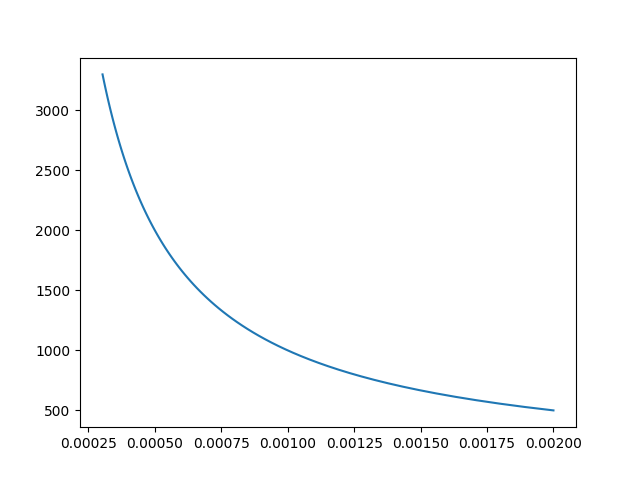

In [5]:
plt.figure(1)
plt.cla()
plt.plot(Slist,Rlist)
plt.show()

In [6]:
minRes = 3.3e3
def calcR(Rset):
    Rvals = np.zeros(32)
    for i in range(32):
        bin = (i & (1 << np.arange(5))[::-1] > 0).astype(int)
        conductance = 1/Rset
        Sadj = np.sum(conductance*bin) + 1/minRes
        Rvals[i] = 1/Sadj

    return Rvals


In [7]:
minResAlt = 510
def calcRAlt(Rset):
    Rvals = np.zeros(32)
    for i in range(32):
        bin = (i & (1 << np.arange(5))[::-1] > 0).astype(int)
        Radj = np.sum(Rset*bin) + minResAlt
        Rvals[i] = Radj

    return Rvals


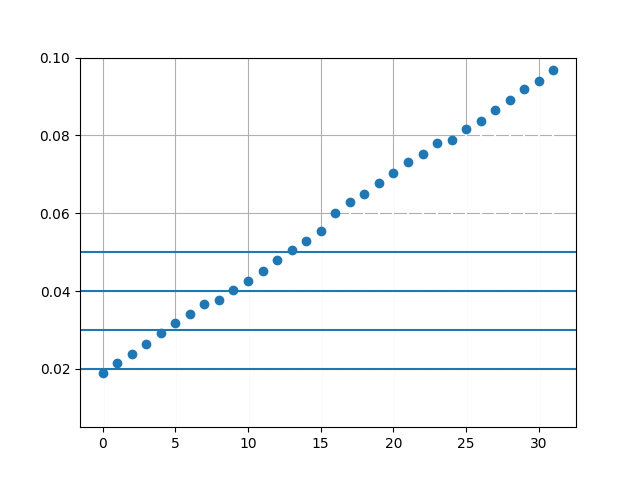

In [13]:
plt.figure(2)
plt.cla()
Rvals = np.array((3.3e3,1.5e3,820,390,220))
out = calcRAlt(Rvals)
# out = Rvals+510
outSorted = out
Isorted = calcIin(outSorted)
plt.stem(Isorted,linefmt='white',markerfmt='C0')
plt.axhline(50e-3)
plt.axhline(40e-3)
plt.axhline(30e-3)
plt.axhline(20e-3)
plt.ylim(5e-3,100e-3)
plt.grid(True,"both")
plt.show()

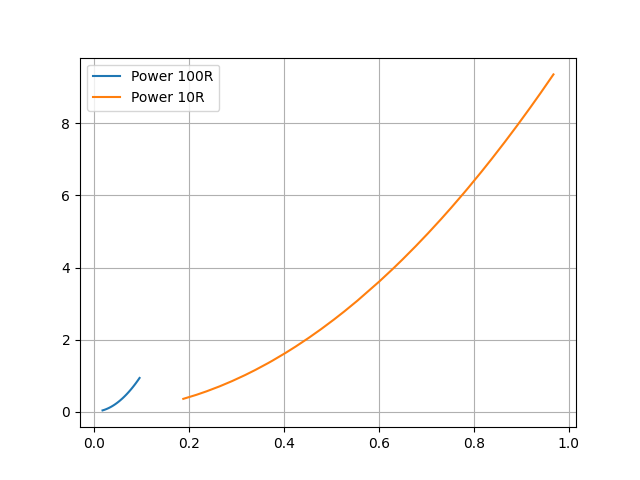

In [14]:
plt.figure(3)
plt.cla()
Voltage = Isorted*100
plt.plot(Isorted,Voltage**2/100,label="Power 100R")
plt.plot(Isorted*10,Voltage**2/10 ,label="Power 10R")
plt.legend()
plt.grid()
plt.show()


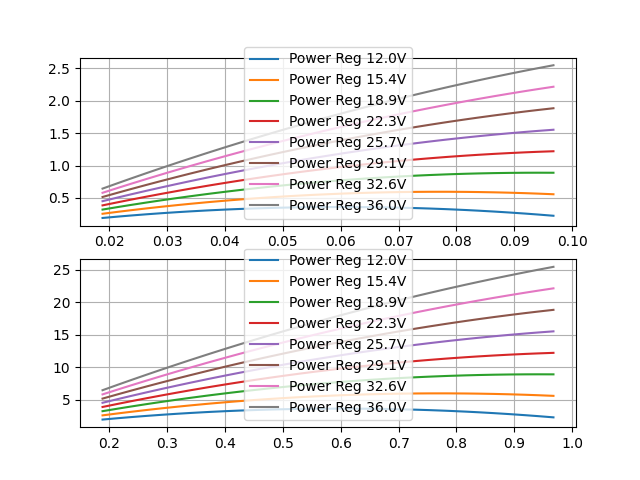

In [15]:
fig, axs = plt.subplots(2,1)
plt.cla()
Vin = np.linspace(12,36,8)
Voltage = Isorted*100
for v in Vin:
    Vd = v-Voltage
    Pd = Vd*Isorted
    axs[0].plot(Isorted,Pd,label="Power Reg "+str(round(v,1))+"V")
axs[0].legend()
axs[0].grid()

for v in Vin:
    Vd = v-Voltage
    Pd = Vd*Isorted*10
    axs[1].plot(Isorted*10,Pd,label="Power Reg "+str(round(v,1))+"V")
axs[1].legend()
axs[1].grid()
plt.show()